### Exercise: Frequentist Coverage and Loss of Identifiability in NV Center ODMR

**The Physics Context:**
In quantum sensing, Nitrogen-Vacancy (NV) centers in diamond are read out using Optically Detected Magnetic Resonance (ODMR). You sweep a microwave frequency across the resonance and count the emitted photons. At the resonance frequency, the fluorescence drops, creating a "dip" in the spectrum.

To make the numerics manageable, our variable $\nu$ represents the **detuning** (in MHz) from the expected resonance (which is typically ~2.87 GHz). Therefore, a sweep from -5 to +5 means we are sweeping $\pm 5$ MHz around the center.

**The Statistical Model:**
Because we are counting independent photons, the number of observed photons $N_i$ at each discrete frequency point $\nu_i$ follows a Poisson distribution. The expected rate $\lambda(\nu_i)$ is modeled as a constant background $B$ minus a Lorentzian dip of amplitude $A$ (the contrast) and width $\gamma$:
$$\lambda(\nu_i) = B - A \frac{\gamma^2}{(\nu_i - \nu_0)^2 + \gamma^2}$$

The physical meaning and typical values of the parameters for our toy model are:
* **$B$ (Background):** Base photon counts per measurement point (True value = 1000).
* **$A$ (Amplitude/Contrast):** The depth of the dip in photon counts.
* **$\nu_0$ (Center):** The true resonance detuning (True value = 0.0 MHz).
* **$\gamma$ (Linewidth):** The width of the resonance (True value = 1.0 MHz).

**The Goal:**
If the true contrast $A$ is very weak, the signal gets buried in the Poisson noise ($\sqrt{B}$). In this regime, the linewidth $\gamma$ becomes completely unconstrained (a flat likelihood). This is called a "loss of identifiability." Your goal is to study how this affects the 2D Confidence Region of $(A, \gamma)$ and whether Wilks' theorem (which predicts $2\Delta\text{NLL}$ follows a $\chi^2$ distribution) holds at varying signal-to-noise ratios.

**Step-by-Step Instructions:**

1. **The Generative Model & Likelihood:** * Write a Python function `rate_model(nu, B, A, nu0, gamma)` that returns the expected rate.
   * Write a function to generate toy datasets with Poisson fluctuations for the number of photons at 50 discrete points of the frequency detuning $\nu$ between -5 and 5.
   * Write a custom Negative Log-Likelihood (NLL) function for Poisson data.
2. **The Fitter:**
   * Set up an `iminuit.Minuit` object. Set sensible limits (e.g., $B>0, A>0, \gamma>0$).
3. **Checking 2D Coverage (The Core Loop):**
   * Write a function that runs $N_{toys} = 300$ pseudo-experiments for a given true value of $A$.
   * For each toy, perform a fit to find the MLE for the parameters.
   * Then calculate a 2D confidence interval at 68.3% level for the parameters of interest $A$ and $\gamma$.
   * Check if the 2D confidence interval includes the true value of $A$ and $\gamma$ and keep track of the coverage fraction.
4. **Visualizing Wilks' Theorem:**
   * We use a test statistic $t$ based on the profiled likelihood ratio to get the 2D confidence interval of the POIs $A$ and $\gamma$.
   * Plot a histogram of your $t$ values. Overlay the theoretical PDF predicted by Wilks' theorem.
5. **Scanning the Contrast:**
   * Run your loop for three scenarios: a "Strong Signal" ($A=500$), a "Weak Signal" ($A=100$), and a "Very Weak Signal" ($A=20$).
   * Visualize the 2D profile likelihood contours for these three cases. What happens to the contour when the signal is very weak?
   * Compare the coverage fractions and the shapes of the test statistic histograms across the three scenarios.

In [1]:
!pip install iminuit

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from iminuit import Minuit
from scipy.stats import poisson
from iminuit.cost import UnbinnedNLL
from scipy.stats import chi2
# ==========================================
# GENERATIVE MODEL & LIKELIHOOD
# ==========================================

def rate_model(nu, B, A, nu0, gamma):
    """Lorentzian dip on a constant background."""
    return B - A * (gamma**2 / ((nu - nu0)**2 + gamma**2))

def generate_toy(nu, B, A, nu0, gamma):
    """Generates a toy dataset with Poisson fluctuations."""
    expected_rate = rate_model(nu, B, A, nu0, gamma)
    # Ensure physical rates (no negative expected photons)
    expected_rate = np.maximum(expected_rate, 1e-6)
    return np.random.poisson(expected_rate)

def create_nll(nu_data, N_data):
    """Creates a custom Poisson NLL function bound to specific data."""
    def nll(B, A, nu0, gamma):
        lam = rate_model(nu_data, B, A, nu0, gamma)
        lam = np.maximum(lam, 1e-6) # Protect against log(0) or negative rates
        # Calculate the negative log-likelihood using scipy
        return -np.sum(poisson.logpmf(N_data, mu=lam))

    return nll

def fit(nu_scan, N_scan, B_scan, A_scan, nu0_scan, gamma_scan):
    nll = create_nll(nu_scan, N_scan)
    m = Minuit(nll, B=B_scan, A=A_scan, nu0=nu0_scan, gamma=gamma_scan)
    m.limits['B'] = (0.001, None)
    m.limits['A'] = (0.001, None)
    m.limits['gamma'] = (0.001, None)
    m.migrad()
    m.hesse()
    return m

In [3]:
def fit(nu_scan, N_scan, B_scan, A_scan, nu0_scan, gamma_scan):

    nll = create_nll(nu_scan, N_scan)

    m = Minuit(nll, B=B_scan, A=A_scan, nu0=nu0_scan, gamma=gamma_scan)

    m.limits['B'] = (0.001, None)
    m.limits['A'] = (0.001, None)
    m.limits['gamma'] = (0.001, None)


    m.migrad()
    m.hesse()

    return m

def core_loop(B, A, nu0, gamma, N_toys):
    t_vals = []
    coverage = 0
    n_success = 0

    for _ in range(N_toys):
        nu_toys = np.linspace(-5, 5, 51)

        # Generate data
        N_data = generate_toy(nu_toys, B, A, nu0, gamma)
        # Global fit
        m = fit(nu_toys, N_data, B, A, nu0, gamma)

        if not m.valid:
            continue

        n_success += 1
        nll_min = m.fval

        # Profile likelihood at TRUE (A, gamma)
        nll = create_nll(nu_toys, N_data)

        #nll over Bp, nu0p fixing A, gamma. I minimize wrt B, A
        def profiled_nll(Bp, nu0p):
            return nll(Bp, A, nu0p, gamma)

        m_prof = Minuit(profiled_nll,
                        Bp=m.values["B"],
                        nu0p=m.values["nu0"])

        m_prof.migrad()

        if not m_prof.valid:
            continue

        nll_prof = m_prof.fval

        # Test statistic
        t = 2 * (nll_prof - nll_min)
        t_vals.append(t)

        # 2D 68% CL
        if t <= 2.30:
            coverage += 1

    return coverage / n_success, np.array(t_vals)

In [4]:

# =========================
# PARAMETRI VERI
# =========================

A_true = [500, 100, 20]
gamma_true = 1
B_true = 1000
nu0_true = 0
N_toys = 1000

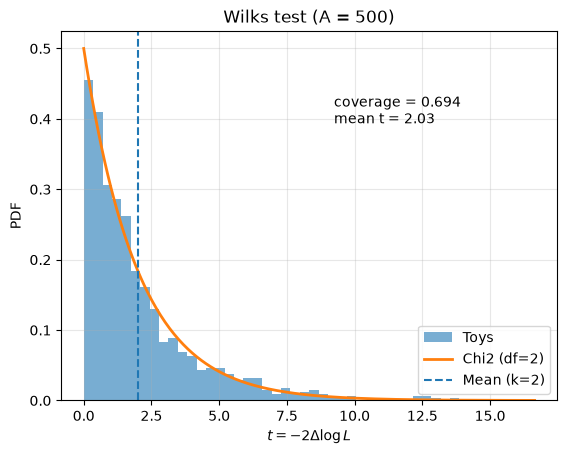

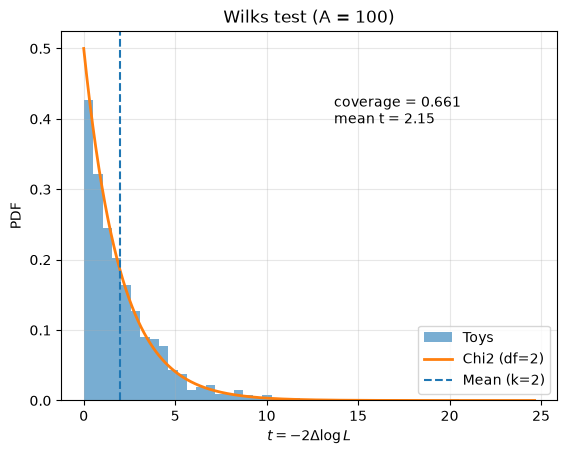

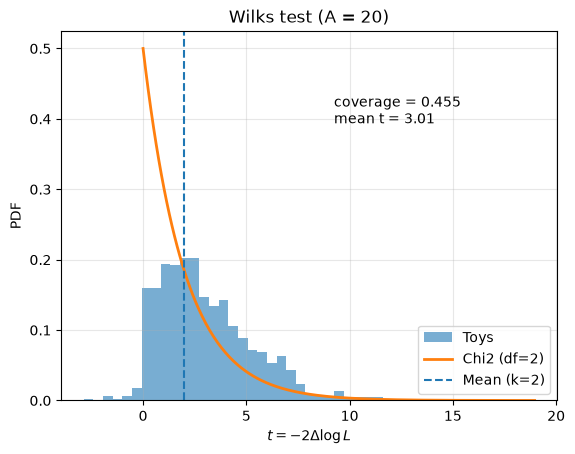

In [5]:
for A in A_true:
    coverage, t_vals = core_loop(B_true, A, nu0_true, gamma_true, N_toys)

    if len(t_vals) == 0:
        print(f"No valid toys for A = {A}")
        continue

    plt.figure()

    # Histogram
    plt.hist(t_vals, bins=40, density=True, alpha=0.6, label="Toys")

    # Theoretical chi2 (df = 2)
    x = np.linspace(0, max(t_vals) * 1.2, 300)
    plt.plot(x, chi2.pdf(x, df=2), linewidth=2, label="Chi2 (df=2)")

    # Expected mean line
    plt.axvline(2, linestyle="--", label="Mean (k=2)")

    # Compute mean t
    mean_t = np.mean(t_vals)

    # Text box (coverage + mean)
    plt.text(0.55, 0.75,
             f"coverage = {coverage:.3f}\nmean t = {mean_t:.2f}",
             transform=plt.gca().transAxes)

    plt.title(f"Wilks test (A = {A})")
    plt.xlabel(r"$t = -2\Delta \log L$")
    plt.ylabel("PDF")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

#@title { vertical-output: true}

Qui ho dimostrato che t si distribuisce com chi. Se non avessi fatto la profile liklelihood, avrei ottenuto un chi con 4 dof dato i 4 parametri di stima. il primo global fit serve a fissare i parametri reali di stima (avrei potuto usare direttamente i valori definiti in partenza) e dopo di che uso due di questi come fissi (A e gamma) e rifitto con una nuova funzione nei paramtrei di B e nu0. Questo due t li uso per costruirmi t. Con 4 liberi, avrei fatto due fit identici e fatta la differenza. in questo caso avrei avuto chi dof4. I dati li creo usando valori reali fissati. Avrei potuto usare direttamente questi valori per la stima di confronto di t.
Il coverage non è nientaltro che l'area sottesa della -2NLL a una fissata treshold. Per 1dof, sigma corrisponde a 1, 2dof a 2.3 ecc.
Verificata la distribuzione chi, a un fit posso associare un p_value e confrontarlo con la chi attesa per verificare la bontà della stima.
L'errore della stima lo fisso con il converage mettendomi come limite lo stimatore tale che NLL sia 1/2.3 ecc in base ai dof.


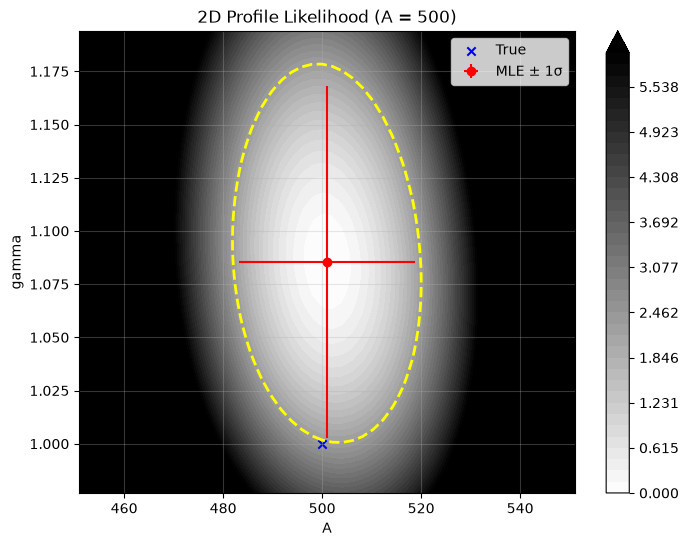

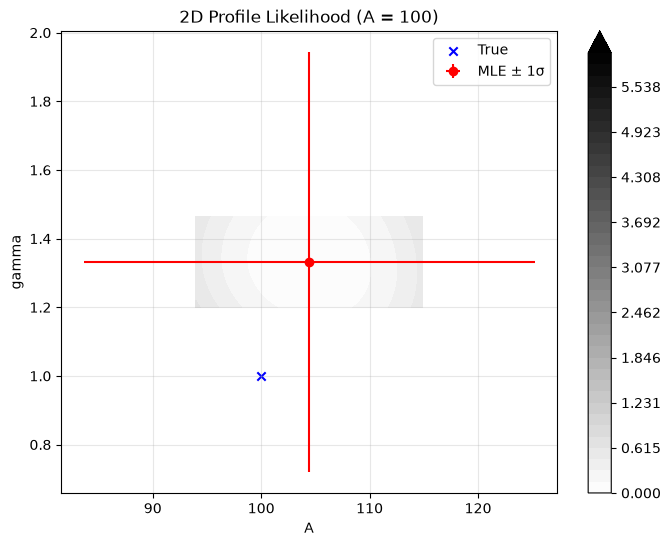

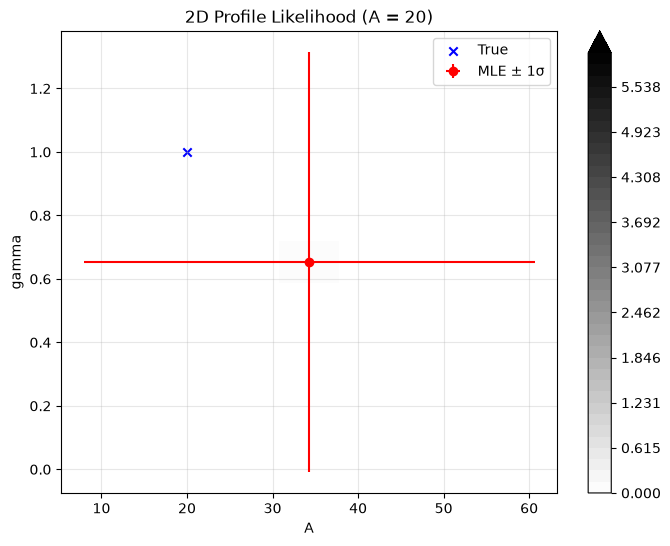

In [6]:
for A_true_val in A_true:
    nu = np.linspace(-5, 5, 51)
    data = generate_toy(nu, B_true, A_true_val, nu0_true, gamma_true)
    nll = create_nll(nu, data)
    m = fit(nu, data, B_true, A_true_val, nu0_true, gamma_true)

    if not m.valid:
        continue

    A_hat = m.values['A']
    gamma_hat = m.values['gamma']
    min_nll = m.fval
    A_err = m.errors['A']
    gamma_err = m.errors['gamma']

    A_scan = np.linspace(A_hat * 0.9, A_hat * 1.1, 50)
    gamma_scan = np.linspace(gamma_hat * 0.9, gamma_hat * 1.1, 50)
    A_grid, G_grid = np.meshgrid(A_scan, gamma_scan)
    nll_grid = np.full_like(A_grid, np.nan)

    for i in range(A_grid.shape[0]):
        for j in range(A_grid.shape[1]):

            A_val = A_grid[i, j]
            gamma_val = G_grid[i, j]


            def profiled_nll(Bp, nu0p):
                return nll(Bp, A_val, nu0p, gamma_val)

            m_prof = Minuit(profiled_nll,
                            Bp=m.values["B"],
                            nu0p=m.values["nu0"])
            m_prof.migrad()
            if m_prof.valid:
                nll_grid[i, j] = m_prof.fval


    delta_nll = 2 * (nll_grid - min_nll)

    plt.figure(figsize=(8, 6))
    contourf = plt.contourf(A_grid, G_grid, delta_nll,
                           levels=np.linspace(0, 6, 40),
                           cmap='binary', extend='max')
    plt.colorbar(contourf)
    plt.contour(A_grid, G_grid, delta_nll,
                levels=[2.30],
                colors='yellow', linestyles='dashed',
                linewidths=2)
    plt.errorbar(A_hat, gamma_hat,
                 xerr=A_err, yerr=gamma_err,
                 fmt='o', color='red', label='MLE ± 1σ')
    plt.scatter(A_true_val, gamma_true,
                color='blue', marker='x', label='True')
    plt.xlabel("A")
    plt.ylabel("gamma")
    plt.title(f"2D Profile Likelihood (A = {A_true_val})")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    #@title { vertical-output: true}

Questo plot non è nientaltro che il plot dall'alto di una 2NLL in funzione di due parametri di stima. In 3 paramtrei, avrei un'elissoide (pillola) in cui sui tre assi ho le stime, mentre il valore di 2NLL sarebbe la densità/scala colori. Il cerchio giallo è il taglio a 2.3 2NLL per intervallo di confidenza a 1$\sigma$. In 3 parametri, avrei delle superfici elissoidi all'interno della nube della NLL.
Minos resituisce solo il minimo della parabola 3D, mentre per costruirla completamente, bisogna fare uno scan di A,gamma; usarli per fissare i due parametri del fit, rifare il fit in funzione di B, nu0, estrarre il valore nll a cui va sotratto nll stimato direttamente dal fit globale (oppure ricavanto usando direttamente i valori reali). Praticamente marginalizzo il mio modello, fissando i due parametri di interesse e svolgendo il fit sugli altri; ad ogni A,gamma ho un valore di NLL dipendete da queste due scelte.